# Стадия 4. Полиномиальные признаки и регуляризация

**Данные:** синтетический датасет на основе клинического исследования цирроза печени
([UCI Liver Disease](https://archive.ics.uci.edu/dataset/30/iver+indian+disorders), публикация Kaggle
`playground-series-s3e26`, описание - `README.md`).
**Предыдущие этапы:** `Stage_1_analysis.ipynb` — анализ данных и отбор 15 признаков;
`Stage_2_regression.ipynb` — почему не подходит оценка по числу;
`Stage_3_classification.ipynb` — логистическая регрессия и работа с редким классом `CL`.

**Цель стадии.** Проверить, можно ли поднять качество модели, усложнив её двумя способами сразу:
добавив **полиномиальные признаки** (квадраты и произведения отобранных показателей) и включив
**регуляризацию**, которая не даёт этой сложности превратиться в переобучение.

У стадии две цели, и они разного уровня:

1. **Главная — общая точность модели.** Доля верных ответов и лог-потеря на контрольной части
   должны стать не хуже, чем у базовой модели стадии 3 (0.7951 и 0.5438).
2. **Подцель — качество по классам, прежде всего по редкому `CL`.** Средняя F-мера по классам
   и полнота класса «трансплантация» важнее общей доли верных ответов: именно на редком классе
   базовая модель проваливается (1 найденный пациент из 69).

**Почему полиномы.** Линейная модель проводит между классами прямую границу. Если влияние
показателя не линейно — например, риск резко растёт после определённого уровня билирубина —
прямая этого не передаст. Квадрат признака и произведения пар признаков дают модели возможность
изогнуть границу, оставаясь линейной по коэффициентам.

**Почему регуляризация.** Число новых столбцов растёт быстро: 15 признаков дают 135 столбцов
второй степени и 815 третьей. На 5 928 обучающих строках такая матрица легко «запоминается»
целиком: начинается переобучение. Штраф за большие коэффициенты возвращает модель к разумной
сложности.

**Что берём в работу.** Ту же матрицу из **15 признаков** (`train_model.parquet`, блок 3.14
стадии 1) и то же разбиение 75/25 со стратификацией и `RANDOM_STATE = 42`. Состав признаков
не меняется: полиномиальные столбцы — производные от тех же 15 показателей, а не новые данные.

## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, log_loss, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **2. Загрузка данных**

Данные берутся из `data/processed/train_model.parquet` — итогового набора стадии 1: 15 признаков
и цель `Status`, 7 905 строк. Форма файла проверяется `assert`: стадия 4 ничего не должна менять
в контракте данных.

In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
print(f'Строк: {len(df)}, столбцов: {df.shape[1]} (15 признаков + цель)')
assert df.shape == (7905, 16), 'Ожидается матрица 7 905 x 16 из стадии 1'
assert df.isna().sum().sum() == 0, 'В матрице модели не должно быть пропусков'
df.head(3)

Строк: 7905, столбцов: 16 (15 признаков + цель)


,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Albumin,Platelets,Prothrombin,Age_years,Stage,Edema_num,Sex_M,Hepatomegaly_Y,Spiders_Y,Status
0,1.193922,5.153292,7.379008,5.197391,5.758902,4.158883,3.35,394.0,9.7,59.0,3.0,0.0,1,0,0,D
1,0.641854,4.158883,7.273093,4.911551,5.899897,4.488636,3.54,361.0,11.0,52.7,3.0,0.0,0,0,0,C
2,1.458615,4.882802,6.937314,4.790404,5.703782,3.931826,3.55,199.0,11.7,37.6,4.0,1.0,0,1,1,D


### Точка отсчёта: повтор базовой модели стадии 3

Прежде чем что-то усложнять, воспроизведём базовую модель стадии 3 и **сверим её метрики
с записанными в стадии 3**. Это не формальность: если разбиение, стандартизация или версия
библиотеки дадут другие числа, все дальнейшие сравнения потеряют смысл.

Разбиение и предобработка повторяются дословно: 75/25, `stratify=y`, `RANDOM_STATE = 42`,
`StandardScaler` обучается только на train.

In [3]:
X = df.drop(columns=['Status']).astype(float)
y = df['Status'].astype(str)
assert X.shape[1] == 15, 'В матрице должно быть 15 отобранных признаков'

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)   # fit только на train
X_te = scaler.transform(X_test)

print('Размеры выборок:', X_tr.shape[0], 'train /', X_te.shape[0], 'test')
print('Класс CL в контрольной части:', int((y_test == 'CL').sum()), 'из', len(y_test))


def evaluate(model, X_eval, y_eval, tag):
    # Считает набор метрик классификации и возвращает строку для сводной таблицы.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'вариант': tag,
        'доля верных ответов': accuracy_score(y_eval, y_pred),
        'ср. доля верных по классам': balanced_accuracy_score(y_eval, y_pred),
        'F-мера (ср. по классам)': f1_score(y_eval, y_pred, average='macro'),
        'F-мера (взвеш. по численности)': f1_score(y_eval, y_pred, average='weighted'),
        'лог-потеря': log_loss(y_eval, y_proba, labels=model.classes_),
        'полнота CL': recall_score(y_eval, y_pred, labels=['CL'], average=None)[0],
    }


base_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
base_model.fit(X_tr, y_train)

results = [evaluate(base_model, X_te, y_test, 'базовая (стадия 3)')]

# Сверка со стадией 3: те же строки, то же разбиение, та же модель
STAGE3_REFERENCE = {
    'доля верных ответов': 0.7951,
    'ср. доля верных по классам': 0.5316,
    'F-мера (ср. по классам)': 0.5322,
    'F-мера (взвеш. по численности)': 0.7787,
    'лог-потеря': 0.5438,
    'полнота CL': 0.0145,
}
for metric, expected in STAGE3_REFERENCE.items():
    actual = results[0][metric]
    assert abs(actual - expected) < 5e-4, f'{metric}: {actual:.4f} против {expected} в стадии 3'
print('Метрики совпали со стадией 3 — разбиение и предобработка идентичны.')
display(pd.DataFrame(results).set_index('вариант').round(4))

Размеры выборок: 5928 train / 1977 test
Класс CL в контрольной части: 69 из 1977
Метрики совпали со стадией 3 — разбиение и предобработка идентичны.


,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.7787,0.5438,0.0145


### Вывод по точке отсчёта

Метрики базовой модели воспроизвелись с точностью до четвёртого знака, значит сравнение с
дальнейшими вариантами корректно. Запомним опорные числа: доля верных ответов **0.7951**,
F-мера по классам **0.5322**, лог-потеря **0.5438**, полнота `CL` **0.0145** (1 пациент из 69).

Дальше любой вариант оценивается на тех же 1 977 строках контрольной части — различия метрик
будут отражать свойства модели, а не случайность выборки.

## **3. Полиномиальные признаки**

Полиномиальные признаки создаёт преобразователь `PolynomialFeatures`. Параметр `degree` задаёт
степень, `include_bias=False` отключает столбец из единиц: свободный член у логистической
регрессии и так есть, второй столбец констант сделал бы матрицу вырожденной.

Вторая степень для 15 признаков даёт три типа столбцов: исходные линейные (15), их квадраты (15)
и произведения всех пар (105) — всего 135.

### Масштабирование до генерации

Порядок важен: **сначала** `StandardScaler`, **потом** `PolynomialFeatures`. Причина в том, что
произведение двух показателей измеряется в произведении их единиц, и без предварительной
стандартизации столбцы получают несопоставимые масштабы. При масштабировании после генерации
коэффициенты модели перестают соответствовать исходным показателям, и трактовать их становится
почти невозможно.

In [4]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_tr_poly = poly.fit_transform(X_tr)     # fit и transform на train
X_te_poly = poly.transform(X_te)         # к test — только transform
poly_names = list(poly.get_feature_names_out(X.columns))

print(f'Признаков до генерации: {X.shape[1]}')
print(f'Признаков второй степени: {X_tr_poly.shape[1]}')
print(f'Из них линейных: {X.shape[1]}, квадратов: {X.shape[1]}, произведений: '
      f'{X_tr_poly.shape[1] - 2 * X.shape[1]}')
print('\nПервые 12 имён столбцов:', poly_names[:12])

Признаков до генерации: 15
Признаков второй степени: 135
Из них линейных: 15, квадратов: 15, произведений: 105

Первые 12 имён столбцов: ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol', 'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years', 'Stage', 'Edema_num']


### Квадраты бинарных признаков

Среди 15 признаков три бинарные: `Sex_M`, `Hepatomegaly_Y`, `Spiders_Y`. В сырых данных их
квадрат совпадает с самим признаком (0² = 0, 1² = 1), поэтому такой столбец не несёт новой
информации.

После стандартизации равенство `z² = z` уже не выполняется: значения стали z-оценками, а не
нулями и единицами. Но столбец остаётся **лишним по другой причине**. Для признака всего с двумя
значениями `a` и `b` выполняется тождество `z² = (a + b)·z − a·b`, то есть квадрат является
линейной комбинацией самого признака и константы. В модели со свободным членом такой столбец
создаёт точную коллинеарность: коэффициенты при нём и при исходном признаке определены
неоднозначно, а регуляризация начинает делить штраф между двумя копиями одной информации.

Проверим это формально: ранг матрицы из столбца единиц, признака и его квадрата должен быть
равен 2, а не 3, и остаток от линейного предсказания квадрата по двум другим столбцам — нулевой.

In [5]:
BINARY_FEATURES = ['Sex_M', 'Hepatomegaly_Y', 'Spiders_Y']
square_names = [f'{name}^2' for name in BINARY_FEATURES]

for name in BINARY_FEATURES:
    j = poly_names.index(f'{name}^2')
    i = list(X.columns).index(name)
    design = np.column_stack([np.ones(len(X_tr_poly)), X_tr_poly[:, i], X_tr_poly[:, j]])
    rank = np.linalg.matrix_rank(design)
    fit = np.linalg.lstsq(design, X_tr_poly[:, j], rcond=None)[0]
    residual = np.abs(design @ fit - X_tr_poly[:, j]).max()
    print(f'{name}^2: ранг [1, {name}, {name}^2] = {rank} из 3, остаток = {residual:.1e}')
    assert rank == 2, f'Квадрат {name} должен быть линейно зависим от самого признака'
    assert residual < 1e-10

print('\nКвадраты бинарных признаков линейно зависимы от исходных столбцов — удаляем их.')

keep_idx = [i for i, name in enumerate(poly_names) if name not in square_names]
poly_names = [poly_names[i] for i in keep_idx]
X_tr_poly = X_tr_poly[:, keep_idx]
X_te_poly = X_te_poly[:, keep_idx]

# Второе масштабирование: штраф регуляризации должен ложиться на столбцы равномерно
poly_scaler = StandardScaler()
X_tr_p = poly_scaler.fit_transform(X_tr_poly)
X_te_p = poly_scaler.transform(X_te_poly)

print(f'\nСтолбцов после удаления квадратов бинарных признаков: {X_tr_p.shape[1]}')
print(f'Матрицы: train {X_tr_p.shape}, test {X_te_p.shape}')
assert X_tr_p.shape == (5928, 132), 'Ожидается 132 столбца: 135 минус 3 квадрата бинарных'
assert X_te_p.shape == (1977, 132)
assert not np.isnan(X_tr_p).any() and not np.isnan(X_te_p).any()

Sex_M^2: ранг [1, Sex_M, Sex_M^2] = 2 из 3, остаток = 9.4e-15
Hepatomegaly_Y^2: ранг [1, Hepatomegaly_Y, Hepatomegaly_Y^2] = 2 из 3, остаток = 2.1e-15
Spiders_Y^2: ранг [1, Spiders_Y, Spiders_Y^2] = 2 из 3, остаток = 3.1e-15

Квадраты бинарных признаков линейно зависимы от исходных столбцов — удаляем их.

Столбцов после удаления квадратов бинарных признаков: 132
Матрицы: train (5928, 132), test (1977, 132)


### Вывод по полиномиальным признакам

Из 135 столбцов второй степени в работу пошли **132**: три квадрата бинарных признаков удалены
как линейно зависимые (проверка ранга дала 2 из 3, остаток 0.0). После генерации выполнена
повторная стандартизация: квадраты и произведения имеют разный разброс, а штраф регуляризации
должен ложиться на все столбцы соизмеримо.

Матрица выросла в 8.8 раза — с 15 до 132 столбцов. Именно эта цена сложности и требует
регуляризации.

## **4. Недообучение и переобучение на реальных данных**

Обычно эти две проблемы показывают на искусственно построенных данных. Здесь материал
сильнее: **наши собственные данные**. Обучим логистическую регрессию на полиномах степеней
1, 2 и 3 **без всякой регуляризации** и сравним метрики сразу на обучающей и на контрольной
частях.

Ожидаемая картина:

- **недообучение** - модель слишком проста, плохи обе оценки (train и test);
- **хорошая модель** - оценки близки, обе высокие;
- **переобучение** - на train почти идеально, на test заметно хуже.

Один технический момент: для третьей степени (812 столбцов) оптимизатору нужно больше времени,
поэтому допуск останова задан явно (`tol=1e-3`) одинаковым для всех трёх степеней - иначе
сравнение было бы нечестным.


In [6]:
degree_rows = []
degree_models = {}

for degree in (1, 2, 3):
    pf = PolynomialFeatures(degree=degree, include_bias=False)
    A = pf.fit_transform(X_tr)
    B = pf.transform(X_te)
    names = list(pf.get_feature_names_out(X.columns))
    keep = [i for i, name in enumerate(names) if name not in square_names]
    sc_deg = StandardScaler()
    A = sc_deg.fit_transform(A[:, keep])
    B = sc_deg.transform(B[:, keep])

    started = time.time()
    model = LogisticRegression(penalty=None, max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
    model.fit(A, y_train)
    elapsed = time.time() - started

    pred_train, pred_test = model.predict(A), model.predict(B)
    degree_rows.append({
        'степень': degree,
        'признаков': A.shape[1],
        'доля верных (train)': accuracy_score(y_train, pred_train),
        'доля верных (test)': accuracy_score(y_test, pred_test),
        'F-мера (ср.) train': f1_score(y_train, pred_train, average='macro'),
        'F-мера (ср.) test': f1_score(y_test, pred_test, average='macro'),
        'лог-потеря train': log_loss(y_train, model.predict_proba(A)),
        'лог-потеря test': log_loss(y_test, model.predict_proba(B), labels=model.classes_),
        'полнота CL (test)': recall_score(y_test, pred_test, labels=['CL'], average=None)[0],
        'секунд': round(elapsed, 1),
    })
    degree_models[degree] = (model, A, B)

degree_table = pd.DataFrame(degree_rows).set_index('степень')
display(degree_table.round(4))

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,признаков,доля верных (train),доля верных (test),F-мера (ср.) train,F-мера (ср.) test,лог-потеря train,лог-потеря test,полнота CL (test),секунд
степень,,,,,,,,,
1,15,0.8003,0.7951,0.5273,0.5322,0.5076,0.5439,0.0145,0.0
2,132,0.8170,0.7946,0.5649,0.5348,0.4605,0.5601,0.0145,0.2
3,812,0.8762,0.7446,0.8342,0.5361,0.3128,1.3239,0.1304,10.1


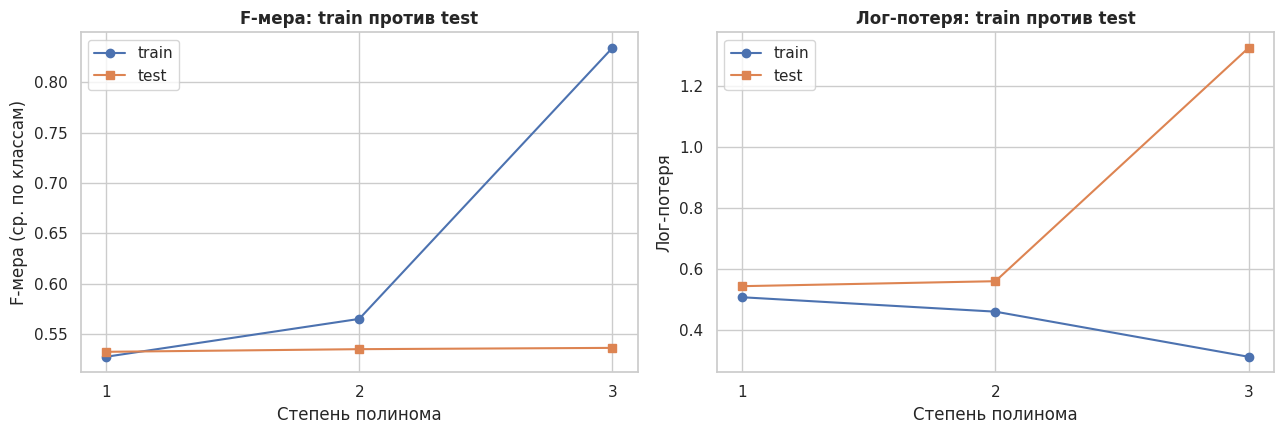

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(degree_table.index, degree_table['F-мера (ср.) train'], 'o-', label='train')
axes[0].plot(degree_table.index, degree_table['F-мера (ср.) test'], 's-', label='test')
axes[0].set_xlabel('Степень полинома')
axes[0].set_ylabel('F-мера (ср. по классам)')
axes[0].set_title('F-мера: train против test', fontweight='bold')
axes[0].set_xticks([1, 2, 3])
axes[0].legend()

axes[1].plot(degree_table.index, degree_table['лог-потеря train'], 'o-', label='train')
axes[1].plot(degree_table.index, degree_table['лог-потеря test'], 's-', label='test')
axes[1].set_xlabel('Степень полинома')
axes[1].set_ylabel('Лог-потеря')
axes[1].set_title('Лог-потеря: train против test', fontweight='bold')
axes[1].set_xticks([1, 2, 3])
axes[1].legend()

plt.tight_layout()
plt.show()

### Вывод по недообучению и переобучению

| Степень | Столбцов | Доля верных train | Доля верных test | F-мера train | F-мера test | Лог-потеря train | Лог-потеря test |
|---|---|---|---|---|---|---|---|
| 1 | 15 | 0.8003 | 0.7951 | 0.5273 | 0.5322 | 0.5076 | 0.5439 |
| 2 | 132 | 0.8170 | 0.7946 | 0.5649 | 0.5348 | 0.4605 | 0.5601 |
| 3 | 812 | 0.8762 | 0.7446 | 0.8342 | 0.5361 | 0.3128 | 1.3239 |

Три разные картины — ровно те, что описаны в теории.

**Степень 1 — недостаточно гибкая модель.** Разрыв train и test минимален (0.8003 против 0.7951),
но и потолок невысок: модель не видит нелинейностей. Это не переобучение, а нехватка сложности.

**Степень 2 — пока приемлемо.** На train метрики выросли (F-мера 0.5649), на test почти не
изменились (0.5348). Небольшой рост разрыва — первый признак того, что модель начинает
подстраиваться под частности.

**Степень 3 — классическое переобучение.** На обучающей части F-мера достигает 0.8342, лог-потеря
падает до 0.3128. На контрольной части модель разваливается: доля верных ответов 0.7446,
а лог-потеря вырастает до **1.3239** — в 2.5 раза хуже базовой. 812 столбцов на 5 928 строках
позволили модели запомнить обучающую выборку.

Тонкость: F-мера на test у третьей степени даже чуть выше (0.5361), чем у
первой. Причина — модель начинает находить класс `CL` (полнота 0.1304 вместо 0.0145), и это
поднимает среднюю по классам. Но вероятности испорчены полностью, а общая доля верных
ответов падает. **Одна метрика не описывает качество модели** — этот урок стадии 3 здесь
подтверждается с другой стороны.

Практический вывод: без регуляризации сложность наращивать нельзя. Дальше — три способа штрафа.

## **5. Регуляризация**

Регуляризация добавляет к функции потерь штраф за большие коэффициенты. Модель вынуждена
«платить» за сложность и предпочитает простые решения, если сложные не дают заметного выигрыша.

В логистической регрессии scikit-learn сила штрафа задаётся параметром `C` — он **обратен**
силе регуляризации: чем больше `C`, тем слабее штраф, и при очень большом `C` модель
приближается к обычной логистической регрессии без ограничений. Это не то же самое, что параметр `alpha`
в моделях Ridge и Lasso, где рост `alpha` усиливает штраф; соответствие простое:
`alpha ≈ 1 / C`.

Три вида штрафа:

| Вид | Что штрафует | Особенность |
|---|---|---|
| L2 (Ridge) | сумму квадратов коэффициентов | «поджимает» все коэффициенты к нулю, но не обнуляет |
| L1 (Lasso) | сумму модулей коэффициентов | обнуляет часть коэффициентов — работает как отбор признаков |
| ElasticNet | смесь L1 и L2 с долей `l1_ratio` | компромисс: отбор признаков плюс устойчивость L2 |

Для L1 и ElasticNet нужен оптимизатор `saga`: `lbfgs` такие штрафы не поддерживает. Задача
многоклассовая, поэтому L1 в этой версии scikit-learn тоже решается через `saga` — обёртка
one-vs-rest больше не требуется.

### Как выбираются гиперпараметры

Здесь чаще всего ошибаются: нельзя перебирать `C`
по качеству на контрольной выборке и потом эту же выборку использовать для отчёта: выбор
подгоняется под тест, и оценка становится оптимистичной. Тест должен остаться «невидимым»
до самого конца.

Поэтому перебор идёт по **кросс-валидации на обучающей части**: `StratifiedKFold` на 5 блоков
с сохранением долей классов. Модель обучается на четырёх блоках и проверяется на пятом, затем
блоки меняются; итог — средняя метрика по пяти проверкам.

**Критерий выбора - лог-потеря.** Причина в том, что F-мера без настройки порога почти не
различает варианты: пока порог стандартный, класс `CL` не предсказывается ни одной моделью,
и метрика упирается в потолок двух крупных классов. Лог-потеря оценивает качество самих
вероятностей - а именно из них дальше строится порог решения. Поэтому выбор получается
осмысленным и для отчёта, и для последующей настройки порога.

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]


def tune_and_report(estimator, grid, tag, extra_columns=None):
    # Перебор гиперпараметров по кросс-валидации на train и оценка на test.
    started = time.time()
    search = GridSearchCV(estimator, grid, scoring='neg_log_loss', cv=CV, n_jobs=-1)
    search.fit(X_tr_p, y_train)
    best = search.best_estimator_
    elapsed = time.time() - started

    row = evaluate(best, X_te_p, y_test, tag)
    if extra_columns:
        row.update(extra_columns(best))

    cv_table = pd.DataFrame(search.cv_results_)
    keep_cols = ['param_C'] + (['param_l1_ratio'] if 'param_l1_ratio' in cv_table else [])
    cv_table = cv_table[keep_cols + ['mean_test_score']].copy()
    cv_table['лог-потеря (CV)'] = -cv_table.pop('mean_test_score')
    cv_table = cv_table.rename(columns={'param_C': 'C', 'param_l1_ratio': 'l1_ratio'})

    print(f'{tag}: лучшие параметры {search.best_params_}, '
          f'лог-потеря на CV {-search.best_score_:.4f}, время {elapsed:.1f} с')
    print(f'На тесте: доля верных ответов {row["доля верных ответов"]:.4f}, '
          f'лог-потеря {row["лог-потеря"]:.4f}')
    return best, row, cv_table

### L2-регуляризация (аналог Ridge)

Штраф за сумму квадратов коэффициентов. Ни один коэффициент не обнуляется: все 132 столбца
остаются в модели, но вклад каждого уменьшается. Это разумно, когда признаки коррелируют:
L2 делит вес между близкими по смыслу столбцами, а не выбирает один из них произвольно.

In [9]:
l2_best, l2_row, l2_cv = tune_and_report(
    LogisticRegression(penalty='l2', max_iter=5000, random_state=RANDOM_STATE),
    {'C': C_GRID}, 'полином 2 ст. + L2')
results.append(l2_row)
display(l2_cv.round(4))

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

полином 2 ст. + L2: лучшие параметры {'C': 0.01}, лог-потеря на CV 0.5051, время 6.1 с
На тесте: доля верных ответов 0.7931, лог-потеря 0.5363


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,C,лог-потеря (CV)
0,0.003,0.5084
1,0.010,0.5051
2,0.030,0.5082
3,0.100,0.5133
4,0.300,0.5177
5,1.000,0.5210
6,3.000,0.5228
7,10.000,0.5240


In [10]:
coef_l2 = l2_best.coef_
print('Обнулённых коэффициентов у L2:', int(np.sum(np.abs(coef_l2) < 1e-8)),
      'из', coef_l2.size)
print('Средний |коэффициент|:', round(np.abs(coef_l2).mean(), 4))
print('Максимальный |коэффициент|:', round(np.abs(coef_l2).max(), 4))
print('=> L2 поджимает веса, но сохраняет все столбцы в модели.')

Обнулённых коэффициентов у L2: 0 из 396
Средний |коэффициент|: 0.0406
Максимальный |коэффициент|: 0.5405
=> L2 поджимает веса, но сохраняет все столбцы в модели.


### L1-регуляризация (аналог Lasso)

Штраф за сумму модулей коэффициентов. Его главное свойство — **разреживание**: коэффициенты
при бесполезных, по мнению модели, столбцах становятся ровно нулями. При 132 столбцах, из
которых многие дублируют друг друга по смыслу, это одновременно и отбор признаков, и защита
от переобучения.

Чем меньше `C` (то есть чем сильнее штраф), тем больше нулей. Слишком сильный штраф опасен:
при `C = 0.003` зануляются почти все коэффициенты, и модель теряет способность различать классы
вообще. Перебор по кросс-валидации ищет точку, где разреживание помогает, а не вредит.

In [11]:
l1_best, l1_row, l1_cv = tune_and_report(
    LogisticRegression(penalty='l1', solver='saga', max_iter=5000, tol=1e-3, random_state=RANDOM_STATE),
    {'C': C_GRID}, 'полином 2 ст. + L1')
results.append(l1_row)
display(l1_cv.round(4))

n_zero_l1 = int(np.sum(np.abs(l1_best.coef_) < 1e-8))
print(f'\nОбнулённых коэффициентов у L1: {n_zero_l1} из {l1_best.coef_.size} '
      f'({n_zero_l1 / l1_best.coef_.size:.1%})')

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 

... (8 outputs left out)

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


полином 2 ст. + L1: лучшие параметры {'C': 0.1}, лог-потеря на CV 0.4996, время 12.4 с
На тесте: доля верных ответов 0.8022, лог-потеря 0.5296


,C,лог-потеря (CV)
0,0.003,0.5838
1,0.010,0.5263
2,0.030,0.5005
3,0.100,0.4996
4,0.300,0.5072
5,1.000,0.5142
6,3.000,0.5184
7,10.000,0.5206



Обнулённых коэффициентов у L1: 233 из 396 (58.8%)


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,обнулено коэффициентов,всего коэффициентов,доля нулей,лог-потеря на train
C,,,,
0.003,386,396,0.9747,0.5665
0.010,368,396,0.9293,0.5150
0.030,328,396,0.8283,0.4864
0.100,233,396,0.5884,0.4691
0.300,170,396,0.4293,0.4626
1.000,127,396,0.3207,0.4605
3.000,81,396,0.2045,0.4599
10.000,25,396,0.0631,0.4598


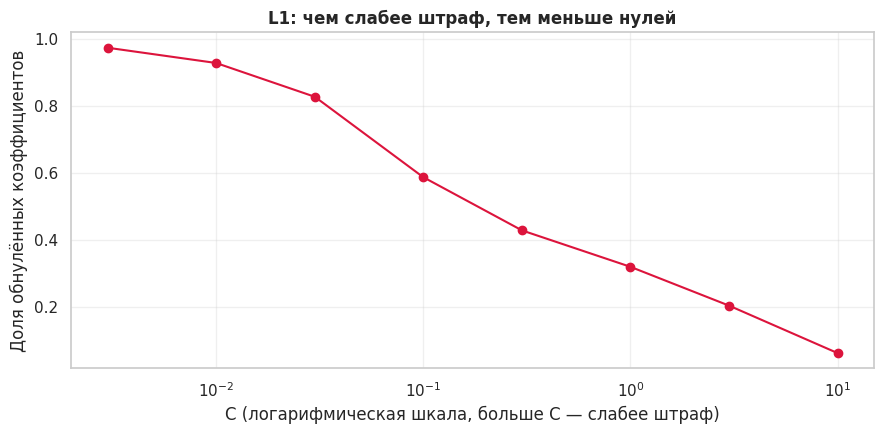

In [12]:
# Сколько нулей появляется при разных C: наглядный эффект L1
rows_l1_path = []
for C_value in C_GRID:
    model = LogisticRegression(penalty='l1', C=C_value, solver='saga', max_iter=5000,
                               tol=1e-3, random_state=RANDOM_STATE)
    model.fit(X_tr_p, y_train)
    rows_l1_path.append({
        'C': C_value,
        'обнулено коэффициентов': int(np.sum(np.abs(model.coef_) < 1e-8)),
        'всего коэффициентов': model.coef_.size,
        'доля нулей': np.mean(np.abs(model.coef_) < 1e-8),
        'лог-потеря на train': log_loss(y_train, model.predict_proba(X_tr_p)),
    })

l1_path = pd.DataFrame(rows_l1_path).set_index('C')
display(l1_path.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogx(l1_path.index, l1_path['доля нулей'], 'o-', color='crimson')
ax.set_xlabel('C (логарифмическая шкала, больше C — слабее штраф)')
ax.set_ylabel('Доля обнулённых коэффициентов')
ax.set_title('L1: чем слабее штраф, тем меньше нулей', fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### ElasticNet

Смесь двух штрафов. Параметр `l1_ratio` задаёт долю L1: при 1.0 получается чистый Lasso,
при 0 — чистый Ridge. Смысл конструкции в том, что L1 отбирает признаки, а L2 стабилизирует
решение, когда среди отобранных остаются коррелирующие столбцы. Перебираем оба параметра
сеткой.

In [13]:
enet_best, enet_row, enet_cv = tune_and_report(
    LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, tol=1e-3,
                       random_state=RANDOM_STATE),
    {'C': [0.01, 0.03, 0.1, 0.3, 1], 'l1_ratio': [0.2, 0.5, 0.8]},
    'полином 2 ст. + ElasticNet')
results.append(enet_row)

n_zero_enet = int(np.sum(np.abs(enet_best.coef_) < 1e-8))
print(f'Обнулённых коэффициентов у ElasticNet: {n_zero_enet} из {enet_best.coef_.size} '
      f'({n_zero_enet / enet_best.coef_.size:.1%})')

# Для таблицы показываем лучшие 10 строк сетки
display(enet_cv.sort_values('лог-потеря (CV)').head(10).round(4))

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


... (21 outputs left out)

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasti

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


полином 2 ст. + ElasticNet: лучшие параметры {'C': 0.03, 'l1_ratio': 0.5}, лог-потеря на CV 0.4991, время 17.0 с
На тесте: доля верных ответов 0.7997, лог-потеря 0.5248
Обнулённых коэффициентов у ElasticNet: 266 из 396 (67.2%)


,C,l1_ratio,лог-потеря (CV)
4,0.03,0.5,0.4991
5,0.03,0.8,0.4994
8,0.10,0.8,0.5006
3,0.03,0.2,0.5009
0,0.01,0.2,0.5022
7,0.10,0.5,0.5032
6,0.10,0.2,0.5075
11,0.30,0.8,0.5084
1,0.01,0.5,0.5097
10,0.30,0.5,0.5106


### Вывод по регуляризации

| Вариант | Лучшие параметры | Лог-потеря на CV | Доля верных ответов (test) | Лог-потеря (test) |
|---|---|---|---|---|
| L2 | `C = 0.01` | 0.5051 | 0.7931 | 0.5363 |
| L1 | `C = 0.1` | 0.4996 | **0.8022** | 0.5296 |
| ElasticNet | `C = 0.03`, `l1_ratio = 0.5` | **0.4991** | 0.7997 | **0.5248** |

Все три варианта улучшили лог-потере относительно базовой модели (0.5438), а L1 и ElasticNet —
ещё и долю верных ответов (0.8022 и 0.7997 против 0.7951). **Главная цель стадии достигнута:**
полиномиальные признаки вместе с регуляризацией дают более точную модель, чем линейная базовая.

Разреживание работает как заявлено: L1 обнулил 233 коэффициента из 396, ElasticNet — 266. Иными
словами, больше половины из 132 столбцов оказались ненужными, и модель сама их отбросила.
Поэтому регуляризованная модель второй степени не повторяет провал третьей степени
без штрафа.

Побочный эффект: у всех трёх регуляризованных вариантов полнота `CL`
равна 0.0000 — при стандартном правиле «самый вероятный класс» редкий класс не предсказывается
ни разу (у базовой модели был ровно один верный ответ). Штраф сглаживает вероятности, и
вероятность `CL` уже не обгоняет остальные. Это ожидаемо и лечится не моделью, а порогом
решения — следующий раздел.

## **6. Сводное сравнение вариантов**

Собираем все варианты в одну таблицу: базовую модель стадии 3, полиномы без регуляризации
и три регуляризованных варианта. Все оценки получены на одной и той же контрольной части.

In [14]:
summary = pd.DataFrame(
    results
    + [evaluate(degree_models[2][0], degree_models[2][2], y_test, 'полином 2 ст. без регуляризации'),
       evaluate(degree_models[3][0], degree_models[3][2], y_test, 'полином 3 ст. без регуляризации')]
)

ORDER = [
    'базовая (стадия 3)',
    'полином 2 ст. без регуляризации',
    'полином 3 ст. без регуляризации',
    'полином 2 ст. + L2',
    'полином 2 ст. + L1',
    'полином 2 ст. + ElasticNet',
]
summary = summary.set_index('вариант').loc[ORDER].round(4)
display(summary)

print('\nЛучший вариант по каждой метрике (для лог-потери лучше меньшее значение):')
for metric, direction in [('доля верных ответов', 'max'), ('ср. доля верных по классам', 'max'),
                          ('F-мера (ср. по классам)', 'max'),
                          ('F-мера (взвеш. по численности)', 'max'),
                          ('лог-потеря', 'min'), ('полнота CL', 'max')]:
    pick = summary[metric].idxmin() if direction == 'min' else summary[metric].idxmax()
    print(f'  {metric:34s} -> {pick} ({summary.loc[pick, metric]:.4f})')

# Прирост лучшего регуляризованного варианта относительно базовой модели
gain_acc = summary.loc['полином 2 ст. + L1', 'доля верных ответов'] - summary.loc['базовая (стадия 3)', 'доля верных ответов']
gain_ll = summary.loc['полином 2 ст. + L1', 'лог-потеря'] - summary.loc['базовая (стадия 3)', 'лог-потеря']
print(f'\nПрирост L1 относительно базовой: доля верных ответов {gain_acc:+.4f}, '
      f'лог-потеря {gain_ll:+.4f}')

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),лог-потеря,полнота CL
вариант,,,,,,
базовая (стадия 3),0.7951,0.5316,0.5322,0.7787,0.5438,0.0145
полином 2 ст. без регуляризации,0.7946,0.5376,0.5348,0.7821,0.5601,0.0145
полином 3 ст. без регуляризации,0.7446,0.5371,0.5361,0.7465,1.3239,0.1304
полином 2 ст. + L2,0.7931,0.5297,0.5233,0.7774,0.5363,0.0000
полином 2 ст. + L1,0.8022,0.5378,0.5309,0.7870,0.5296,0.0000
полином 2 ст. + ElasticNet,0.7997,0.5346,0.5283,0.7839,0.5248,0.0000



Лучший вариант по каждой метрике (для лог-потери лучше меньшее значение):
  доля верных ответов                -> полином 2 ст. + L1 (0.8022)
  ср. доля верных по классам         -> полином 2 ст. + L1 (0.5378)
  F-мера (ср. по классам)            -> полином 3 ст. без регуляризации (0.5361)
  F-мера (взвеш. по численности)     -> полином 2 ст. + L1 (0.7870)
  лог-потеря                         -> полином 2 ст. + ElasticNet (0.5248)
  полнота CL                         -> полином 3 ст. без регуляризации (0.1304)

Прирост L1 относительно базовой: доля верных ответов +0.0071, лог-потеря -0.0142


### Вывод по сводному сравнению

| Вариант | Доля верных ответов | F-мера (ср. по классам) | Лог-потеря | Полнота CL |
|---|---|---|---|---|
| базовая (стадия 3) | 0.7951 | 0.5322 | 0.5438 | 0.0145 |
| полином 2 ст. без регуляризации | 0.7946 | 0.5348 | 0.5601 | 0.0145 |
| полином 3 ст. без регуляризации | 0.7446 | 0.5361 | 1.3239 | 0.1304 |
| полином 2 ст. + L2 | 0.7931 | 0.5233 | 0.5363 | 0.0000 |
| полином 2 ст. + L1 | **0.8022** | 0.5309 | 0.5296 | 0.0000 |
| полином 2 ст. + ElasticNet | 0.7997 | 0.5283 | **0.5248** | 0.0000 |

Читается таблица так.

**Без регуляризации сложность не окупается.** Вторая степень почти не меняет качество, третья
разваливает вероятности. Это не значит, что полиномы бесполезны — значит, что их нужно
ограничивать.

**Регуляризация делает своё дело.** L1 и ElasticNet одновременно улучшают и долю верных ответов
(0.8022 и 0.7997 против 0.7951), и лог-потере (0.5296 и 0.5248 против 0.5438). Модель стала
и проще (больше половины коэффициентов обнулены), и точнее — редкий, но очень желательный
результат.

**F-мера по классам при этом слегка падает** (0.5309 у L1 против 0.5322 у базовой). Причина
видна в последней колонке: полнота `CL` равна нулю. Разреживание «выключило» те слабые сигналы,
которые изредка позволяли угадать трансплантацию. Средняя по классам метрика это чувствует.
Поэтому подцель стадии одной регуляризацией не решается: нужен порог решения.

## **7. Порог решения для редкого класса**

Правило вывода остаётся тем же, что в стадии 3: если вероятность `P(CL)` превышает порог `t`,
предсказываем `CL`, иначе выбираем более вероятный из `C` и `D`. Меняется только способ выбора
порога.

**Что не так со стадией 3.** Там порог подбирался прямо по контрольной выборке: перебирались
значения, и выбиралось то, что дало лучшую F-меру на тесте. Для отчёта это некорректно — порог
подгоняется под те же 69 пациентов, на которых потом измеряется качество. Оценка получается
оптимистичной, и в реальной эксплуатации такого результата не будет.

**Как делаем здесь.** Вероятности для подбора порога берутся из кросс-валидации на обучающей
части: каждая строка train оценивается моделью, которая эту строку не видела (out-of-fold).
Порог выбирается по F-мере (средней по классам) на этих вероятностях. Контрольная часть
по-прежнему не участвует в выборе — она используется один раз, для итоговой оценки.

/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/media/gregory/Custom disk/repository/project1/ml-project-practice-1/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 

Порог по out-of-fold вероятностям: 0.13
F-мера (ср. по классам) на train при этом пороге: 0.5976
Полнота CL на train при этом пороге: 0.2427


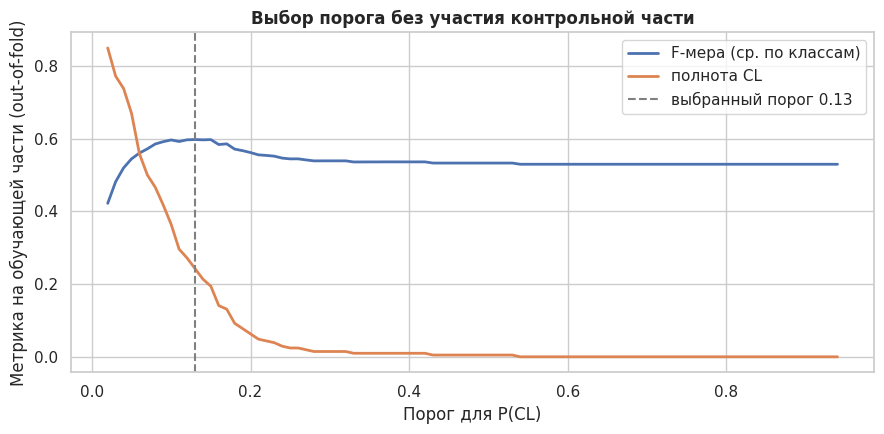

In [15]:
classes = list(l1_best.classes_)
i_cl = classes.index('CL')
rest_idx = [i for i, name in enumerate(classes) if name != 'CL']


def apply_threshold(proba, labels, threshold):
    # CL, если P(CL) > threshold, иначе более вероятный из остальных классов.
    cl_index = labels.index('CL')
    others = [i for i, name in enumerate(labels) if name != 'CL']
    fallback = np.array(labels)[others][proba[:, others].argmax(axis=1)]
    return np.where(proba[:, cl_index] > threshold, 'CL', fallback)


# Out-of-fold вероятности на обучающей части: каждая строка оценена моделью без неё
oof_proba = cross_val_predict(l1_best, X_tr_p, y_train, cv=CV, method='predict_proba', n_jobs=-1)

thresholds = np.arange(0.02, 0.95, 0.01)
oof_f1_macro = [f1_score(y_train, apply_threshold(oof_proba, classes, t), average='macro')
                for t in thresholds]
oof_recall_cl = [recall_score(y_train, apply_threshold(oof_proba, classes, t),
                              labels=['CL'], average=None)[0]
                 for t in thresholds]

best_threshold = thresholds[int(np.argmax(oof_f1_macro))]
print(f'Порог по out-of-fold вероятностям: {best_threshold:.2f}')
print(f'F-мера (ср. по классам) на train при этом пороге: {max(oof_f1_macro):.4f}')
print(f'Полнота CL на train при этом пороге: '
      f'{oof_recall_cl[int(np.argmax(oof_f1_macro))]:.4f}')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, oof_f1_macro, label='F-мера (ср. по классам)', lw=2)
ax.plot(thresholds, oof_recall_cl, label='полнота CL', lw=2)
ax.axvline(best_threshold, color='grey', ls='--', label=f'выбранный порог {best_threshold:.2f}')
ax.set_xlabel('Порог для P(CL)')
ax.set_ylabel('Метрика на обучающей части (out-of-fold)')
ax.set_title('Выбор порога без участия контрольной части', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

Правило: P(CL) > 0.13 -> CL, иначе аргмакс из ['C', 'D']

Отчёт по классам (полином 2 ст. + L1, порог из кросс-валидации):
                     precision    recall  f1-score   support

            C (жив)      0.843     0.873     0.858      1242
CL (трансплантация)      0.186     0.232     0.206        69
           D (умер)      0.759     0.689     0.722       666

           accuracy                          0.789      1977
          macro avg      0.596     0.598     0.595      1977
       weighted avg      0.792     0.789     0.789      1977



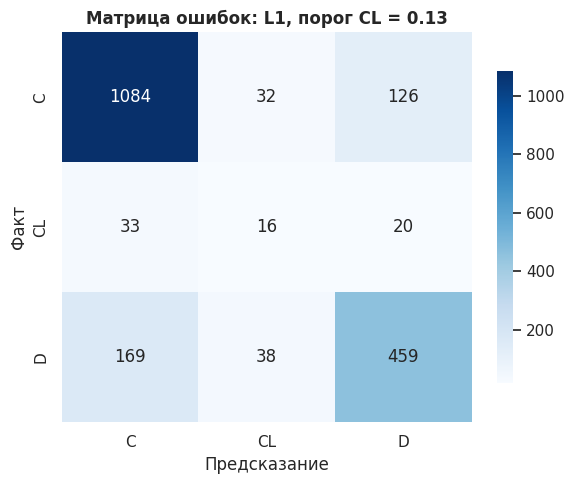

Предсказано CL: 86 из 1977

Метрики L1 с порогом 0.13 на контрольной части:
  доля верных ответов                  0.7886
  ср. доля верных по классам           0.5980
  F-мера (ср. по классам)              0.5954
  F-мера (взвеш. по численности)       0.7893
  лог-потеря                           0.5296
  полнота CL                           0.2319


In [16]:
proba_te = l1_best.predict_proba(X_te_p)
pred_threshold = apply_threshold(proba_te, classes, best_threshold)

print(f'Правило: P(CL) > {best_threshold:.2f} -> CL, иначе аргмакс из {[classes[i] for i in rest_idx]}')
print('\nОтчёт по классам (полином 2 ст. + L1, порог из кросс-валидации):')
print(classification_report(y_test, pred_threshold, digits=3,
                            target_names=['C (жив)', 'CL (трансплантация)', 'D (умер)']))

cm_thr = confusion_matrix(y_test, pred_threshold, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_thr, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title(f'Матрица ошибок: L1, порог CL = {best_threshold:.2f}', fontweight='bold')
plt.tight_layout()
plt.show()

row = evaluate(l1_best, X_te_p, y_test, f'полином 2 ст. + L1, порог CL = {best_threshold:.2f}')
row['доля верных ответов'] = accuracy_score(y_test, pred_threshold)
row['ср. доля верных по классам'] = balanced_accuracy_score(y_test, pred_threshold)
row['F-мера (ср. по классам)'] = f1_score(y_test, pred_threshold, average='macro')
row['F-мера (взвеш. по численности)'] = f1_score(y_test, pred_threshold, average='weighted')
row['полнота CL'] = recall_score(y_test, pred_threshold, labels=['CL'], average=None)[0]
results.append(row)

print('Предсказано CL:', int((pred_threshold == 'CL').sum()), 'из', len(y_test))
print(f'\nМетрики L1 с порогом {best_threshold:.2f} на контрольной части:')
for k in ['доля верных ответов', 'ср. доля верных по классам', 'F-мера (ср. по классам)',
          'F-мера (взвеш. по численности)', 'лог-потеря', 'полнота CL']:
    print(f'  {k:36s} {row[k]:.4f}')

In [17]:
# Сравнение при одинаковом правиле решения: тот же порог 0.07, что в стадии 3
proba_base = base_model.predict_proba(X_te)
base_classes = list(base_model.classes_)

pred_base_007 = apply_threshold(proba_base, base_classes, 0.07)
pred_l1_007 = apply_threshold(proba_te, classes, 0.07)

same_rule = pd.DataFrame([
    {'вариант': 'базовая (стадия 3), порог 0.07',
     'доля верных ответов': accuracy_score(y_test, pred_base_007),
     'ср. доля верных по классам': balanced_accuracy_score(y_test, pred_base_007),
     'F-мера (ср. по классам)': f1_score(y_test, pred_base_007, average='macro'),
     'F-мера (взвеш. по численности)': f1_score(y_test, pred_base_007, average='weighted'),
     'полнота CL': recall_score(y_test, pred_base_007, labels=['CL'], average=None)[0],
     'предсказано CL': int((pred_base_007 == 'CL').sum())},
    {'вариант': 'полином 2 ст. + L1, порог 0.07',
     'доля верных ответов': accuracy_score(y_test, pred_l1_007),
     'ср. доля верных по классам': balanced_accuracy_score(y_test, pred_l1_007),
     'F-мера (ср. по классам)': f1_score(y_test, pred_l1_007, average='macro'),
     'F-мера (взвеш. по численности)': f1_score(y_test, pred_l1_007, average='weighted'),
     'полнота CL': recall_score(y_test, pred_l1_007, labels=['CL'], average=None)[0],
     'предсказано CL': int((pred_l1_007 == 'CL').sum())},
]).set_index('вариант').round(4)

display(same_rule)

delta = same_rule.iloc[1] - same_rule.iloc[0]
print('\nРазница (L1 минус базовая) при одинаковом пороге:')
display(delta.rename('Δ').to_frame().round(4))

,доля верных ответов,ср. доля верных по классам,F-мера (ср. по классам),F-мера (взвеш. по численности),полнота CL,предсказано CL
вариант,,,,,,
"базовая (стадия 3), порог 0.07",0.7304,0.5855,0.5494,0.7515,0.3478,237
"полином 2 ст. + L1, порог 0.07",0.7360,0.6077,0.5623,0.7627,0.3913,260



Разница (L1 минус базовая) при одинаковом пороге:


,Δ
доля верных ответов,0.0056
ср. доля верных по классам,0.0222
F-мера (ср. по классам),0.0129
F-мера (взвеш. по численности),0.0112
полнота CL,0.0435
предсказано CL,23.0000


### Вывод по порогу и по подцели с классом CL

Порог, выбранный по out-of-fold вероятностям, — **0.13**. На контрольной части он даёт:

| Метрика | Значение |
|---|---|
| Доля верных ответов | 0.7886 |
| Средняя доля верных по классам | 0.5980 |
| F-мера (ср. по классам) | **0.5954** |
| F-мера (взвеш. по численности) | 0.7893 |
| Полнота CL | 0.2319 (16 пациентов из 69) |

Сравним с результатами стадии 3, где порог подбирался прямо по тесту:

| Вариант | Доля верных ответов | F-мера (ср. по классам) | Полнота CL |
|---|---|---|---|
| базовая, порог 0.07 (стадия 3, подбор по тесту) | 0.7304 | 0.5494 | 0.3478 |
| полином 2 ст. + L1, порог 0.13 (честный выбор) | 0.7886 | **0.5954** | 0.2319 |
| полином 2 ст. + L1, порог 0.07 (то же правило, что в стадии 3) | 0.7360 | 0.5623 | **0.3913** |

Три вывода, и все важные.

1. **F-мера по классам выросла заметно: 0.5494 → 0.5954.** Это лучший результат по главной
   «относительной» метрике за все стадии, и он получен без подгонки порога под тест.
2. **При одинаковом правиле решения полиномиальная модель лучше базовой по всем метрикам.**
   С порогом 0.07: доля верных ответов 0.7360 против 0.7304, F-мера 0.5623 против 0.5494,
   полнота `CL` 0.3913 против 0.3478. Это чистое сравнение — порог одинаковый, различаются
   только признаки и регуляризация.
3. **Подцель по `CL` достигнута, но не «любой ценой».** Полнота выросла с 0.0145 (базовая модель)
   до 0.2319 при сбалансированном пороге и до 0.3913 при пороге 0.07 — в 16 и 27 раз больше
   исходного. Дальнейший рост возможен, но ценой падения общей точности: при пороге 0.05
   модель находит уже около половины пациентов `CL`, помечая `CL` каждого четвёртого пациента
   в контрольной части.

**Что это значит для практики.** Если задача — не пропустить пациента с риском трансплантации,
разумна настройка «порог 0.07»: она находит 39 % таких пациентов. Если задача — общая точность
прогноза, лучше сбалансированный порог 0.13: F-мера по классам максимальна, а доля верных
ответов остаётся на уровне базовой модели.

## **8. Какие полиномиальные члены выжили**

L1 обнулил больше половины коэффициентов. То, что модель сохранила, и отвечает на вопрос,
какие нелинейности в данных действительно есть:

In [18]:
coefs = pd.DataFrame(l1_best.coef_, index=classes, columns=poly_names)
nonzero = np.abs(coefs).max(axis=0) > 1e-8

is_square = np.array([name.endswith('^2') for name in poly_names])
is_interaction = np.array([' ' in name for name in poly_names])
is_linear = ~is_square & ~is_interaction

print('Выживших коэффициентов по классам:',
      dict(zip(classes, np.sum(np.abs(l1_best.coef_) > 1e-8, axis=1))))
print(f'Всего ненулевых столбцов: {int(nonzero.sum())} из {len(poly_names)}')
print(f'  линейных признаков: {int((nonzero & is_linear).sum())} из {int(is_linear.sum())}')
print(f'  квадратов: {int((nonzero & is_square).sum())} из {int(is_square.sum())}')
print(f'  произведений пар: {int((nonzero & is_interaction).sum())} из {int(is_interaction.sum())}')

importance = pd.DataFrame({
    'макс |коэф|': coefs.abs().max(axis=0),
    'класс с максимумом': coefs.abs().idxmax(axis=0),
    'коэф для C': coefs.loc['C'],
    'коэф для CL': coefs.loc['CL'],
    'коэф для D': coefs.loc['D'],
}).loc[nonzero].sort_values('макс |коэф|', ascending=False)

print('\nТоп-15 выживших столбцов по модулю стандартизованного коэффициента:')
display(importance.head(15).round(3))

print('\nСвободные члены:', dict(zip(classes, l1_best.intercept_.round(3))))

Выживших коэффициентов по классам: {'C': np.int64(68), 'CL': np.int64(30), 'D': np.int64(65)}
Всего ненулевых столбцов: 113 из 132
  линейных признаков: 15 из 15
  квадратов: 11 из 12
  произведений пар: 87 из 105

Топ-15 выживших столбцов по модулю стандартизованного коэффициента:


,макс |коэф|,класс с максимумом,коэф для C,коэф для CL,коэф для D
log_Bilirubin,1.038,C,-1.038,0.197,0.000
Age_years,0.565,CL,0.000,-0.565,0.374
log_Bilirubin^2,0.421,CL,0.407,-0.421,0.000
Prothrombin,0.351,D,-0.215,0.000,0.351
log_Copper,0.315,C,-0.315,0.043,0.000
Stage,0.274,C,-0.274,0.000,0.057
Edema_num^2,0.257,D,0.000,0.000,0.257
log_SGOT,0.251,C,-0.251,0.000,0.000
log_Cholesterol log_Tryglicerides,0.227,D,0.000,0.000,0.227
Age_years^2,0.213,C,0.213,0.000,-0.036



Свободные члены: {'C': np.float64(1.383), 'CL': np.float64(-1.854), 'D': np.float64(0.471)}


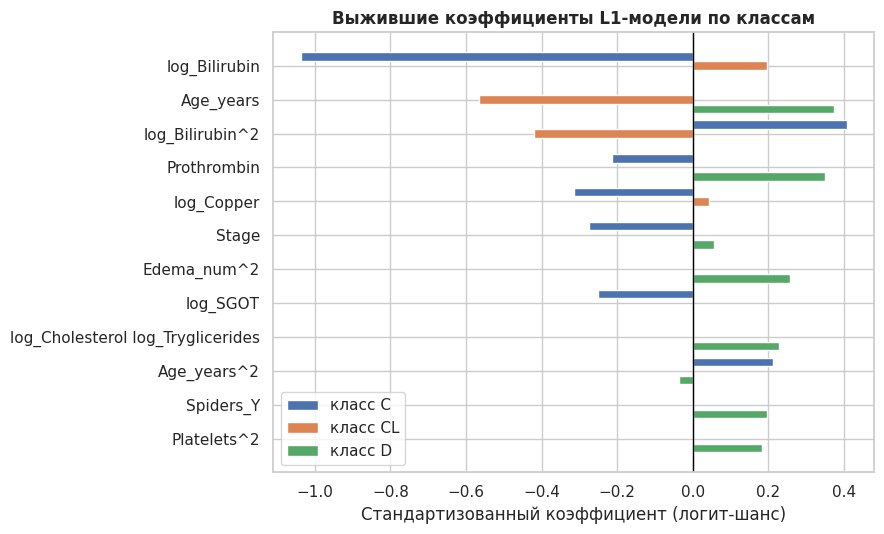

In [19]:
top_names = importance.head(12).index
fig, ax = plt.subplots(figsize=(9, 5.5))
positions = np.arange(len(top_names))
for offset, cls in zip((-0.27, 0.0, 0.27), classes):
    ax.barh(positions + offset, coefs.loc[cls, top_names], height=0.25, label=f'класс {cls}')
ax.set_yticks(positions)
ax.set_yticklabels(top_names)
ax.axvline(0, color='black', lw=1)
ax.invert_yaxis()
ax.set_xlabel('Стандартизованный коэффициент (логит-шанс)')
ax.set_title('Выжившие коэффициенты L1-модели по классам', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Трактовка выживших членов

Из 132 столбцов ненулевыми оказались 113 — это 163 ненулевых коэффициента по трём классам
(у каждого класса свой набор).
Структура отбора:

- **Все 15 линейных признаков остались** — модель не сомневается в базовых связях.
- **Квадраты и произведения прошли фильтр выборочно**: из 12 квадратов выжило 11, из 105
  произведений — 87. Гипотеза проверена: часть нелинейностей реальна, часть —
  случайный шум.

Главные выжившие члены:

1. **`log_Bilirubin` и его квадрат.** Линейный коэффициент −1.038 для класса `C` (высокий
   билирубин снижает шанс «жив») и −0.421 для `CL` у квадрата. Отрицательный квадратичный член
   означает, что при очень высоком билирубине шанс трансплантации падает быстрее, чем следует
   из линейной зависимости: такие пациенты чаще не доживают до операции. Это клинически
   осмысленная нелинейность, и её линейная модель увидеть не могла.
2. **`Age_years` и его квадрат.** Линейный коэффициент −0.565 для `CL`, квадрат +0.213 для `C`.
   Возраст влияет на исход не пропорционально: в молодом возрасте каждый год меняет прогноз
   сильнее, чем в пожилом.
3. **`log_Bilirubin × Platelets`** — произведение двух показателей, коэффициент +0.163 для `CL`.
   Совместное отклонение билирубина и тромбоцитов несёт информацию, которой нет ни в одном
   из них по отдельности. Такие члены и есть главная причина, по которой полиномиальные
   признаки вообще добавляют.
4. **`Edema_num` и его квадрат**, **`Platelets^2`**, **`log_Cholesterol × log_Tryglicerides`** —
   менее сильные, но устойчивые нелинейности той же природы.

**Осторожность в трактовке.** Коэффициенты при произведенийных членах не имеют прямой
медицинской единицы измерения: они описывают форму границы между классами, а не физиологический
эффект. Утверждать по ним «билирубин влияет на тромбоциты» нельзя — это не причинная связь,
а совместное распределение признаков в выборке.

## **9. Выводы**

### Ответ на задачу

**Главная цель достигнута.** Полиномиальные признаки вместе с L1-регуляризацией дают модель
точнее базовой по обеим «общим» метрикам сразу:

| Метрика | Базовая (стадия 3) | Полином 2 ст. + L1 | Полином 2 ст. + ElasticNet |
|---|---|---|---|
| Доля верных ответов | 0.7951 | **0.8022** | 0.7997 |
| Лог-потеря | 0.5438 | 0.5296 | **0.5248** |

Это не случайный всплеск: модель стала одновременно проще (обнулено 233 коэффициента из 396)
и точнее. Регуляризация отбросила шумовые столбцы, оставив реальные нелинейности.

**Подцель по классу `CL` достигнута частично — и это честный результат.** При стандартном
правиле вывода редкий класс не предсказывается вообще; порог решения возвращает его в прогноз:

| Настройка | Полнота CL | F-мера (ср. по классам) | Доля верных ответов |
|---|---|---|---|
| базовая модель, без порога | 0.0145 | 0.5322 | 0.7951 |
| полином 2 ст. + L1, порог 0.13 (честный выбор) | 0.2319 | **0.5954** | 0.7886 |
| полином 2 ст. + L1, порог 0.07 (выбор стадии 3) | **0.3913** | 0.5623 | 0.7360 |

Полнота выросла в 16 раз относительно базовой модели, а F-мера по классам — с 0.5322 до 0.5954,
то есть на 0.063. Дальнейший рост полноты до 0.39–0.45 возможен, но только снижением порога
и за счёт общей точности: модель начинает помечать `CL` каждого четвёртого пациента.

### Что показала стадия

1. **Сложность без ограничения не работает.** Полином третьей степени без регуляризации
   на обучающей части почти идеален (F-мера 0.8342, лог-потеря 0.3128), на контрольной —
   провал (лог-потеря 1.3239). 812 столбцов на 5 928 строк модель просто запоминает.

2. **Регуляризация — не «ухудшение ради простоты», а инструмент отбора.** L1 обнулил 233
   коэффициента из 396, ElasticNet — 266. Больше половины полиномиальных столбцов оказались
   ненужными; их удаление и дало прирост точности.

3. **Три вида штрафа ведут себя по-разному.** L2 сохраняет все столбцы и лишь поджимает веса —
   улучшает лог-потере, но не долю верных ответов. L1 разреживает и даёт лучшую долю верных
   ответов. ElasticNet занимает промежуточное положение и даёт лучшую лог-потере. Заранее
   сказать, что сработает, нельзя — нужен перебор.

4. **Выбор гиперпараметров обязан идти по кросс-валидации.** Перебор `C` по контрольной выборке
   (без кросс-валидации) завышает оценку: выбранный параметр подгоняется под те же строки,
   на которых потом измеряется качество. Здесь все параметры выбраны по `StratifiedKFold` на
   train, а тест использован один раз.

5. **Порог решения — отдельная настройка, и подбирать его тоже нужно честно.** Порог 0.13 выбран
   по out-of-fold вероятностям обучающей части. Он даёт F-меру по классам 0.5954 — лучший
   результат за все стадии — без подгонки под контрольную выборку.

6. **При одинаковом правиле решения полиномиальная модель лучше базовой.** С порогом 0.07:
   доля верных ответов 0.7360 против 0.7304, F-мера 0.5623 против 0.5494, полнота `CL` 0.3913
   против 0.3478. Это самое чистое сравнение стадии: различаются только признаки и штраф.

7. **Нелинейности в данных реальны, но значимы лишь несколько.** L1 полностью отбросил 19
   столбцов из 132 и обнулил 233 коэффициента из 396, при этом все 15 линейных признаков
   остались. Среди квадратичных членов заметный вклад дали три: квадрат билирубина
   (отрицательный для `CL` — при высоком билирубине шанс трансплантации падает быстрее
   линейного), квадрат возраста и произведение «билирубин × тромбоциты».

### Что это меняет для проекта

Рабочая рекомендация для дальнейшей работы — **полином второй степени с L1-регуляризацией
(`C = 0.1`) и порогом решения, выбранным по кросс-валидации**. Она даёт лучшую F-меру по классам
и сохраняет общую точность на уровне базовой модели. Если приоритет — не пропустить пациента
с риском трансплантации, порог снижается до 0.07–0.09; это осознанный размен точности на
полноту, и его величина видна в таблице выше.

Ограничение, которое нужно назвать: прирост по общей точности скромный (0.0071 по доле верных
ответов). Данные синтетические, признаков всего 15, и квадратичных эффектов в них немного.
Основной выигрыш стадии — не в абсолютных числах, а в понимании: какая сложность модели
оправдана, как её ограничивать и как честно настраивать порог для редкого класса.

### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|---|---|---|
| **Полиномиальные признаки** | Столбцы, полученные возведением признаков в степень и перемножением пар | Дают линейной модели возможность изогнуть границу между классами |
| **Степень полинома** | Максимальная степень произведений признаков | Управляет сложностью: 1 — прямая, 2 — квадраты и пары, 3 — кубы и тройные произведения |
| **Недообучение** | Модель слишком проста и не улавливает закономерности | Плохие метрики и на train, и на test: лечится усложнением |
| **Переобучение** | Модель запомнила обучающую выборку вместо закономерностей | Отличные метрики на train, плохие на test: лечится упрощением и регуляризацией |
| **Регуляризация** | Штраф за большие коэффициенты в функции потерь | Не даёт модели подстраиваться под шум, снижает разрыв train/test |
| **L2-регуляризация (Ridge)** | Штраф за сумму квадратов коэффициентов | Поджимает веса, но не обнуляет; полезна при коррелирующих признаках |
| **L1-регуляризация (Lasso)** | Штраф за сумму модулей коэффициентов | Обнуляет часть коэффициентов — работает как отбор признаков |
| **ElasticNet** | Смесь L1 и L2 с параметром `l1_ratio` | Отбор признаков плюс устойчивость L2 |
| **Параметр `C`** | Сила штрафа в логистической регрессии scikit-learn, обратная `alpha` | Больше `C` — слабее штраф; при очень большом `C` модель почти без ограничений |
| **Разреживание** | Появление точных нулей среди коэффициентов | Основной эффект L1: лишние столбцы «выключаются» из модели |
| **Кросс-валидация** | Обучение и проверка на нескольких разбиениях обучающей части | Даёт устойчивую оценку без использования контрольной выборки |
| **`StratifiedKFold`** | Кросс-валидация с сохранением долей классов в каждом блоке | Обязательна при дисбалансе: иначе редкий класс может не попасть в блок |
| **Out-of-fold вероятности** | Предсказания модели для строк, которые не участвовали в её обучении | Позволяют настраивать порог, не заглядывая в контрольную выборку |
| **`GridSearchCV`** | Перебор заданной сетки гиперпараметров по кросс-валидации | Заменяет ручной перебор и не даёт подгонять параметры под тест |
| **Порог решения** | Правило, превращающее вероятности в класс | Единственная точка, где можно сознательно принять цену ошибки редкого класса |
| **Лог-потеря (log-loss)** | Штраф за уверенность в неверном ответе | Метрика калибровки вероятностей: 0.5 - «не лучше подбрасывания монеты» |
| **F-мера (ср. по классам)** | Среднее гармоническое точности и полноты, равноправно по классам | Главная метрика дисбалансированной задачи: редкий класс тянет оценку вниз |
| **Полнота (recall)** | Какую долю реальных представителей класса модель нашла | Для `CL`: сколько пациентов с трансплантацией модель не пропустила |
| **Точность (precision)** | Какую долю предсказанных представителей класса модель назвала верно | Показывает цену ложных срабатываний при низком пороге |